
# 06. AMP Dataset Analysis

## Objective

Characterize the antimicrobial peptide datasets used for MIC prediction against *Escherichia coli* (EC) and *Staphylococcus aureus* (SA), with a focus on comparing training and test data.

## Analysis

- **Dataset summary:** Sample counts and descriptive statistics.
- **Peptide length:** Training and test sequence length distributions.
- **Antimicrobial activity:** Training and test pMIC distributions.
- **Amino acid composition:** Frequencies of the 20 standard amino acids.
- **Physicochemical properties:** Net charge, hydrophobicity, and molecular weight.
- **Sequence similarity:** Similarity between training and test peptides.
- **Length–activity relationship:** Association between peptide length and pMIC.

## Outputs

- `results/dataset/` — Dataset statistics and summary tables.
- `results/dataset/figures/` — Dataset characterization figures.

This notebook uses the final datasets generated in `01_DBAASP_Dataset.ipynb`. No model training is performed.


In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from configs.common import DATA_DIR, RESULT_DIR

# Output directories
DATASET_RESULT_DIR = RESULT_DIR / "dataset"
FIGURE_DIR = DATASET_RESULT_DIR / "figures"

DATASET_RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load final datasets
datasets = {}

for target in ["EC", "SA"]:
    for split in ["Train", "Test"]:
        df = pd.read_csv(DATA_DIR / f"{target}_{split}.csv")

        df["Dataset"] = target
        df["Split"] = split

        datasets[(target, split)] = df

print("Datasets loaded successfully.")

for (target, split), df in datasets.items():
    print(f"{target} / {split}: {len(df):,} peptides")


Datasets loaded successfully.
EC / Train: 7,583 peptides
EC / Test: 843 peptides
SA / Train: 6,592 peptides
SA / Test: 733 peptides


In [5]:

# Calculate dataset statistics
summary_records = []

for (target, split), df in datasets.items():
    summary_records.append({
        "Dataset": target,
        "Split": split,
        "Peptides": len(df),
        "Unique_Sequences": df["sequence"].nunique(),
        "Length_Mean": df["length"].mean(),
        "Length_SD": df["length"].std(),
        "Length_Median": df["length"].median(),
        "Length_Min": df["length"].min(),
        "Length_Max": df["length"].max(),
        "pMIC_Mean": df["pMIC"].mean(),
        "pMIC_SD": df["pMIC"].std(),
        "pMIC_Median": df["pMIC"].median(),
        "pMIC_Min": df["pMIC"].min(),
        "pMIC_Max": df["pMIC"].max(),
    })

dataset_summary = pd.DataFrame(summary_records)

# Save summary
dataset_summary.to_csv(
    DATASET_RESULT_DIR / "dataset_summary.csv",
    index=False
)

display(dataset_summary.round(3))


,Dataset,Split,Peptides,Unique_Sequences,Length_Mean,Length_SD,Length_Median,Length_Min,Length_Max,pMIC_Mean,pMIC_SD,pMIC_Median,pMIC_Min,pMIC_Max
0,EC,Train,7583,7583,18.831,8.331,17.0,5,50,5.034,0.687,5.086,2.222,8.163
1,EC,Test,843,843,19.504,8.734,18.0,5,49,5.024,0.699,5.046,2.046,8.000
2,SA,Train,6592,6592,18.024,8.187,16.0,5,50,4.995,0.651,5.054,2.000,8.448
3,SA,Test,733,733,18.162,8.502,16.0,5,49,5.001,0.646,5.060,2.093,8.383


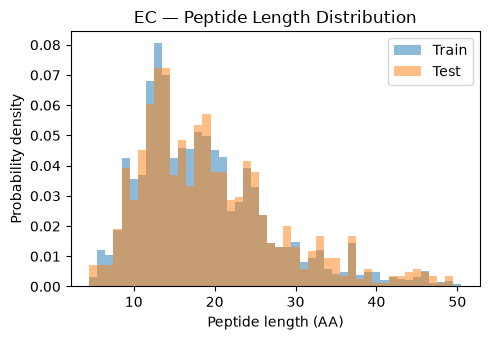

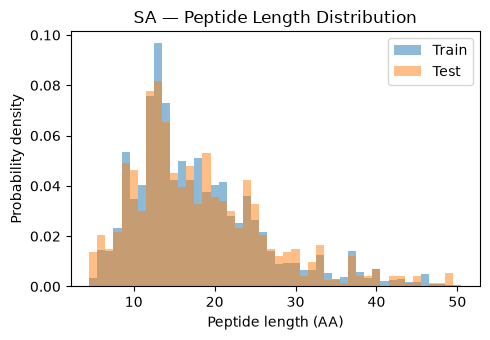

,Dataset,KS_Statistic,KS_pvalue,Wasserstein_Distance
0,EC,0.037670,0.225615,0.682438
1,SA,0.028358,0.651891,0.410299


In [10]:

from scipy.stats import ks_2samp, wasserstein_distance

plt.rcParams.update({"font.size": 10})

length_results = []

for target in ["EC", "SA"]:
    train = datasets[(target, "Train")]["length"].dropna()
    test = datasets[(target, "Test")]["length"].dropna()

    ks = ks_2samp(train, test)
    wd = wasserstein_distance(train, test)

    length_results.append({
        "Dataset": target,
        "KS_Statistic": ks.statistic,
        "KS_pvalue": ks.pvalue,
        "Wasserstein_Distance": wd
    })

    fig, ax = plt.subplots(figsize=(5, 3.5))

    bins = np.arange(4.5, 51.5, 1)

    ax.hist(train, bins=bins, density=True, alpha=0.5, label="Train")
    ax.hist(test, bins=bins, density=True, alpha=0.5, label="Test")

    ax.set_xlabel("Peptide length (AA)")
    ax.set_ylabel("Probability density")
    ax.set_title(f"{target} — Peptide Length Distribution")
    ax.legend()

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / f"{target}_length_distribution.png",
        dpi=300
    )
    plt.show()
    plt.close()

length_comparison = pd.DataFrame(length_results)

length_comparison.to_csv(
    DATASET_RESULT_DIR / "length_comparison.csv",
    index=False
)

display(length_comparison.round(6))


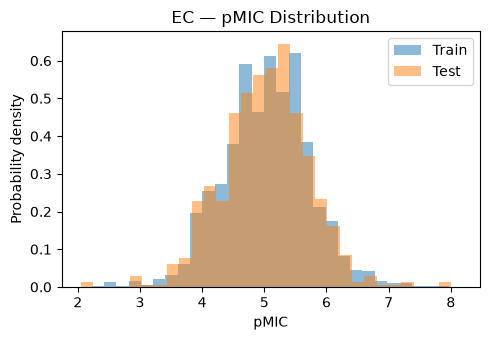

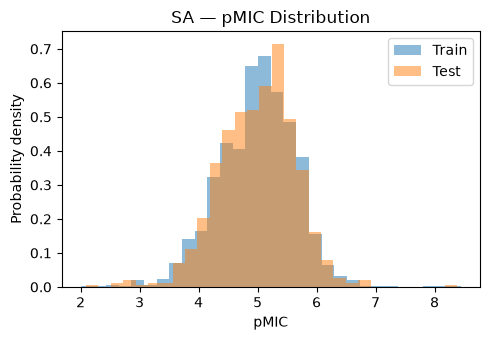

,Dataset,KS_Statistic,KS_pvalue,Wasserstein_Distance
0,EC,0.020540,0.898661,0.020122
1,SA,0.022004,0.898975,0.018641


In [11]:

# Compare pMIC distributions
pmic_results = []

for target in ["EC", "SA"]:
    train = datasets[(target, "Train")]["pMIC"].dropna()
    test = datasets[(target, "Test")]["pMIC"].dropna()

    ks = ks_2samp(train, test)
    wd = wasserstein_distance(train, test)

    pmic_results.append({
        "Dataset": target,
        "KS_Statistic": ks.statistic,
        "KS_pvalue": ks.pvalue,
        "Wasserstein_Distance": wd
    })

    fig, ax = plt.subplots(figsize=(5, 3.5))

    ax.hist(train, bins=30, density=True, alpha=0.5, label="Train")
    ax.hist(test, bins=30, density=True, alpha=0.5, label="Test")

    ax.set_xlabel("pMIC")
    ax.set_ylabel("Probability density")
    ax.set_title(f"{target} — pMIC Distribution")
    ax.legend()

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / f"{target}_pmic_distribution.png",
        dpi=300
    )
    plt.show()
    plt.close()

pmic_comparison = pd.DataFrame(pmic_results)

pmic_comparison.to_csv(
    DATASET_RESULT_DIR / "pmic_comparison.csv",
    index=False
)

display(pmic_comparison.round(6))


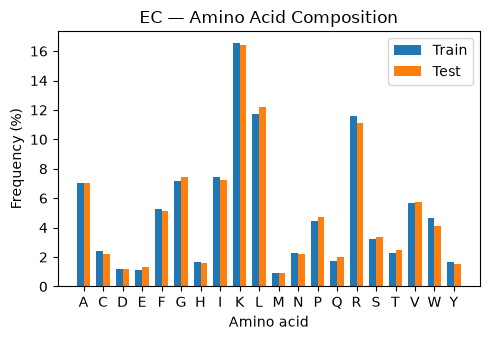

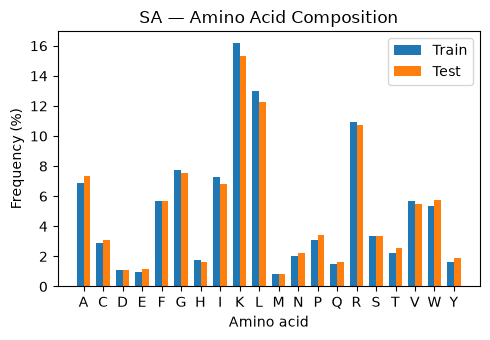

,Dataset,Split,Amino_Acid,Frequency_Percent
0,EC,Train,A,7.052
1,EC,Train,C,2.387
2,EC,Train,D,1.188
3,EC,Train,E,1.115
4,EC,Train,F,5.252
...,...,...,...,...
75,SA,Test,S,3.373
76,SA,Test,T,2.539
77,SA,Test,V,5.498
78,SA,Test,W,5.746


In [15]:
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")
aa_results = []

for target in ["EC", "SA"]:
    freq_dict = {}

    for split in ["Train", "Test"]:
        sequences = datasets[(target, split)]["sequence"].dropna()

        counts = pd.Series({
            aa: sequences.str.count(aa).sum()
            for aa in amino_acids
        })

        frequencies = counts / counts.sum() * 100
        freq_dict[split] = frequencies

        for aa in amino_acids:
            aa_results.append({
                "Dataset": target,
                "Split": split,
                "Amino_Acid": aa,
                "Frequency_Percent": frequencies[aa]
            })

    fig, ax = plt.subplots(figsize=(5, 3.5))

    x = np.arange(len(amino_acids))
    width = 0.35

    ax.bar(
        x - width/2,
        freq_dict["Train"].values,
        width=width,
        label="Train"
    )
    ax.bar(
        x + width/2,
        freq_dict["Test"].values,
        width=width,
        label="Test"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(amino_acids)
    ax.set_xlabel("Amino acid")
    ax.set_ylabel("Frequency (%)")
    ax.set_title(f"{target} — Amino Acid Composition")
    ax.legend()

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / f"{target}_amino_acid_composition.png",
        dpi=300
    )
    plt.show()
    plt.close()

aa_composition = pd.DataFrame(aa_results)

aa_composition.to_csv(
    DATASET_RESULT_DIR / "amino_acid_composition.csv",
    index=False
)

display(aa_composition.round(3))

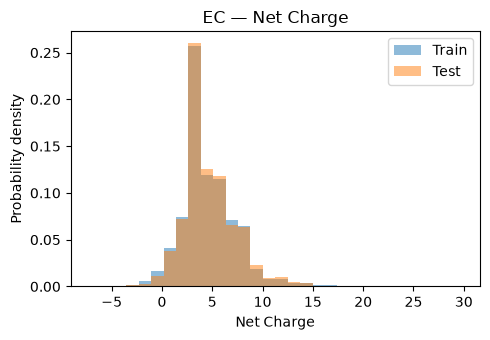

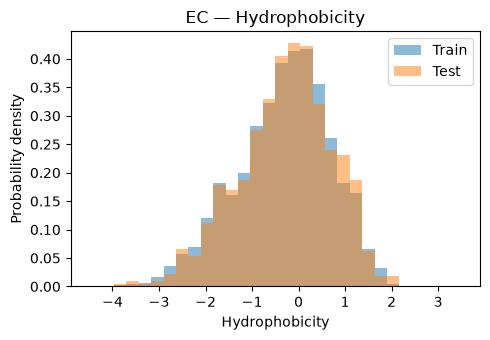

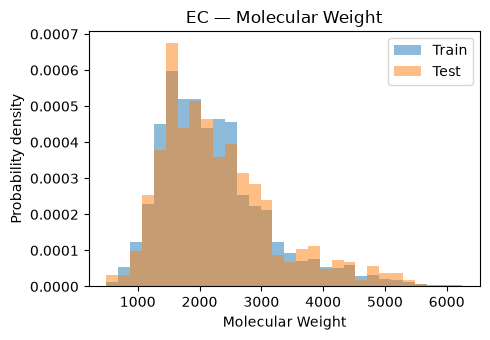

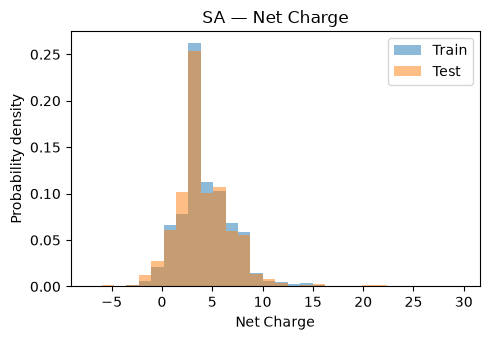

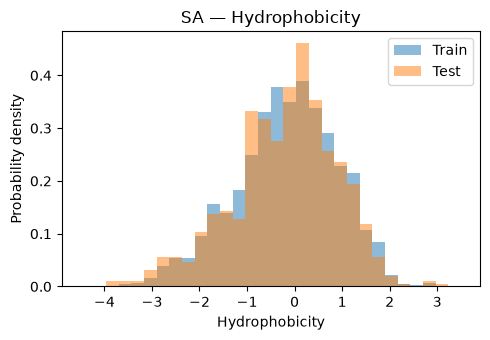

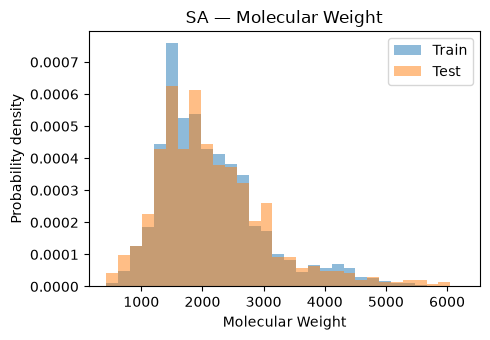

,Dataset,Property,KS_Statistic,KS_pvalue
0,EC,Net_Charge,0.023441,0.788520
1,EC,Hydrophobicity,0.021152,0.878373
2,EC,Molecular_Weight,0.046387,0.073818
3,SA,Net_Charge,0.052113,0.053470
4,SA,Hydrophobicity,0.024126,0.827240
5,SA,Molecular_Weight,0.027312,0.697121


In [16]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from scipy.stats import ks_2samp

plt.rcParams.update({"font.size": 10})

# Calculate physicochemical properties
property_data = []

for (target, split), df in datasets.items():
    for sequence in df["sequence"]:
        peptide = ProteinAnalysis(sequence)

        property_data.append({
            "Dataset": target,
            "Split": split,
            "Sequence": sequence,
            "Net_Charge": peptide.charge_at_pH(7.0),
            "Hydrophobicity": peptide.gravy(),
            "Molecular_Weight": peptide.molecular_weight()
        })

properties = pd.DataFrame(property_data)

properties.to_csv(
    DATASET_RESULT_DIR / "physicochemical_properties.csv",
    index=False
)

# Compare Train and Test distributions
property_names = [
    "Net_Charge",
    "Hydrophobicity",
    "Molecular_Weight"
]

comparison_results = []

for target in ["EC", "SA"]:
    for prop in property_names:
        train = properties.loc[
            (properties["Dataset"] == target) &
            (properties["Split"] == "Train"), prop
        ]

        test = properties.loc[
            (properties["Dataset"] == target) &
            (properties["Split"] == "Test"), prop
        ]

        ks = ks_2samp(train, test)

        comparison_results.append({
            "Dataset": target,
            "Property": prop,
            "KS_Statistic": ks.statistic,
            "KS_pvalue": ks.pvalue
        })

        bins = np.histogram_bin_edges(
            np.concatenate([train, test]), bins=30
        )

        fig, ax = plt.subplots(figsize=(5, 3.5))

        ax.hist(train, bins=bins, density=True, alpha=0.5, label="Train")
        ax.hist(test, bins=bins, density=True, alpha=0.5, label="Test")

        ax.set_xlabel(prop.replace("_", " "))
        ax.set_ylabel("Probability density")
        ax.set_title(f"{target} — {prop.replace('_', ' ')}")
        ax.legend()

        plt.tight_layout()
        plt.savefig(
            FIGURE_DIR / f"{target}_{prop.lower()}.png",
            dpi=300
        )
        plt.show()
        plt.close()

property_comparison = pd.DataFrame(comparison_results)

property_comparison.to_csv(
    DATASET_RESULT_DIR / "physicochemical_comparison.csv",
    index=False
)

display(property_comparison.round(6))
